Data:        2026-11-20
Drawdown:    -11.6%   |   Queda ~45d: -11.0%
VIX          35.89
Spread HY (bps) 352.00
SCORE:       28.0 / 100
CLASSE:      CORREÇÃO


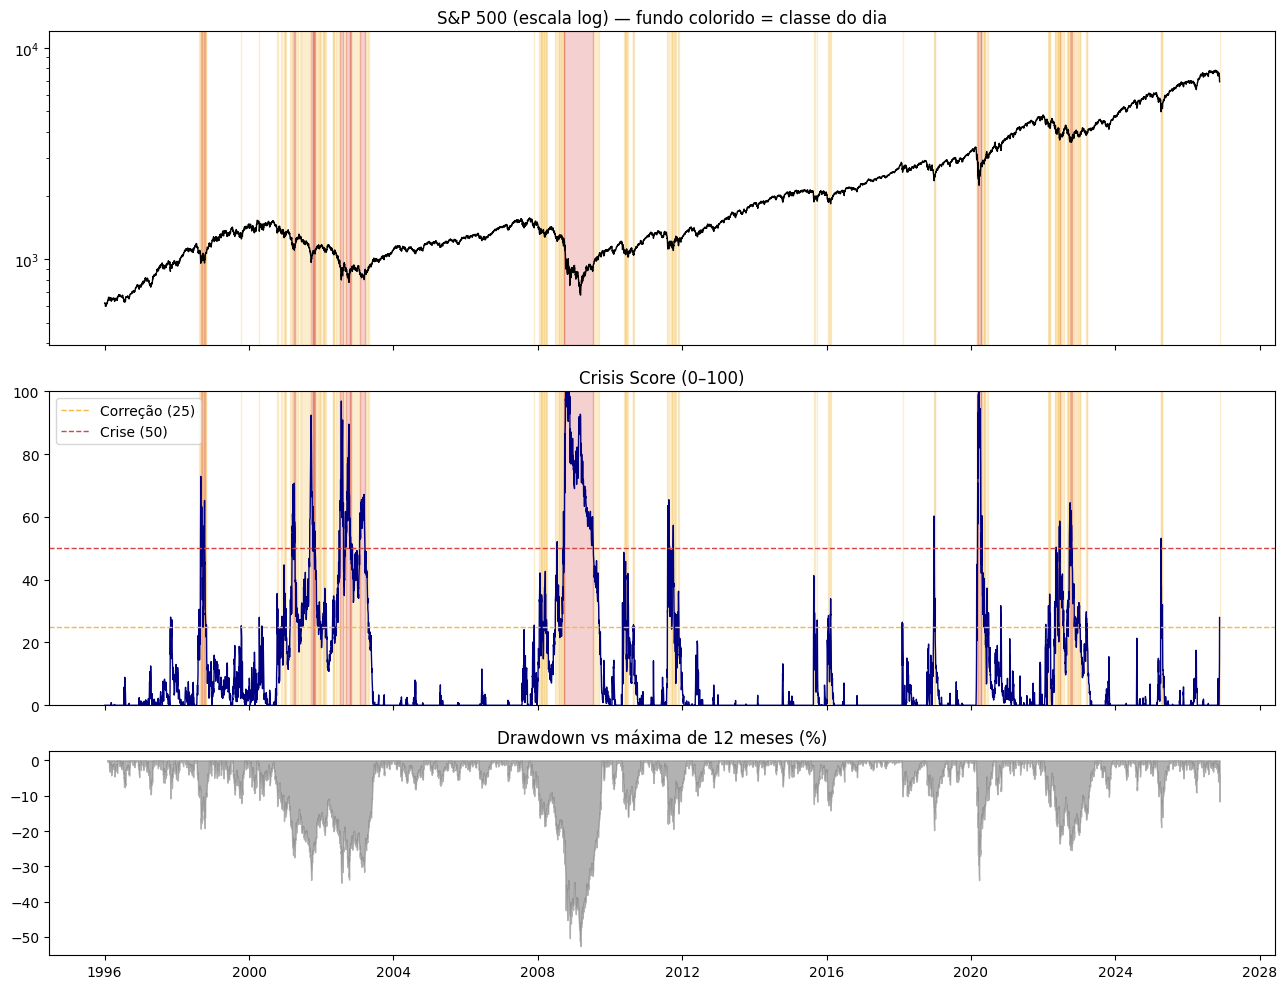


Dias em cada classe:
classe
QUEDA COMUM    6598
CORREÇÃO        783
CRISE           374
sem dados        19

Episódios de CRISE:
  1998-09-03 → 1998-09-04 | score máx 64 | drawdown máx -17.9%
  1998-09-09 → 1998-09-10 | score máx 63 | drawdown máx -17.4%
  1998-10-07 → 1998-10-09 | score máx 65 | drawdown máx -19.2%
  2001-03-16 → 2001-03-26 | score máx 70 | drawdown máx -26.8%
  2001-03-28 → 2001-04-09 | score máx 71 | drawdown máx -27.5%
  2001-09-17 → 2001-10-10 | score máx 92 | drawdown máx -33.8%
  2001-10-12 → 2001-10-19 | score máx 58 | drawdown máx -25.4%
  2001-10-23 → 2001-10-23 | score máx 50 | drawdown máx -24.3%
  2001-11-01 → 2001-11-01 | score máx 51 | drawdown máx -24.3%
  2002-07-12 → 2002-08-13 | score máx 97 | drawdown máx -34.7%
  2002-09-06 → 2002-10-18 | score máx 90 | drawdown máx -33.8%
  2002-10-22 → 2002-10-24 | score máx 54 | drawdown máx -24.7%
  2003-01-29 → 2003-03-18 | score máx 67 | drawdown máx -31.6%
  2008-09-23 → 2008-09-24 | score máx 59 | drawdown

In [4]:

# CÉLULA 1 (v2) — Crisis Score: cálculo, classificação e evolução

!pip install -q yfinance

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

USAR_DEMO = False     # True = dados sintéticos (sem internet)
INICIO = "1996-01-01"  # início do histórico (spread HY do FRED começa em 1996)

#Parâmetros do indicador
# nome: (peso, a = estresse leve, b = nível de crise)
SIGNALS = {
    "drawdown": (30, -0.05,  -0.30),   # queda vs máxima de 12 meses
    "velocity": (15, -0.05,  -0.25),   # retorno em ~45 dias corridos
    "vix":      (20, 20.0,   45.0),    # VIX
    "credit":   (25, 400.0,  1000.0),  # spread high yield (pontos-base)
    "breadth":  (10, 0.50,   0.90),    # % de ações abaixo da média de 200d
}
T_CORRECAO   = 25.0    # score mínimo para "correção"
T_CRISE      = 50.0    # score mínimo para "crise"
DD_MIN_CRISE = -0.15   # drawdown mínimo para rotular "crise"
DD_MIN_CORR  = -0.10   # drawdown mínimo para rotular "correção"
PERSIST_JANELA = 5     # NOVO: "crise" exige persistência: pelo menos PERSIST_MIN
PERSIST_MIN    = 4     #       dos últimos PERSIST_JANELA pregões com critério de crise
LOOKBACK = 252         # pregões da máxima de referência
VEL_WIN  = 31          # ~45 dias corridos em pregões

def _norm(x, a, b):
    return ((x - a) / (b - a)).clip(0, 1)

def classificar(score, dd):
    if pd.isna(score) or pd.isna(dd):
        return "sem dados"
    if score >= T_CRISE and dd <= DD_MIN_CRISE:
        return "CRISE"
    if score >= T_CORRECAO and dd <= DD_MIN_CORR:
        return "CORREÇÃO"
    return "QUEDA COMUM"

def calcular_score(df):
    f = pd.DataFrame(index=df.index)
    f["drawdown"] = df["sp500"] / df["sp500"].rolling(LOOKBACK, min_periods=20).max() - 1
    f["velocity"] = df["sp500"].pct_change(VEL_WIN)
    for col, nome in [("vix", "vix"), ("hy_spread", "credit"), ("breadth", "breadth")]:
        if col in df and df[col].notna().any():
            f[nome] = df[col]
    partes = {k: _norm(f[k], SIGNALS[k][1], SIGNALS[k][2]) for k in SIGNALS if k in f}
    pesos = {k: SIGNALS[k][0] for k in partes}
    wsum = sum(partes[k].notna() * pesos[k] for k in partes)
    raw = sum(partes[k].fillna(0) * pesos[k] for k in partes)
    f["score"] = (100 * raw / wsum).where(wsum > 0)   # renormaliza se faltar sinal
    f["classe"] = [classificar(s, d) for s, d in zip(f["score"], f["drawdown"])]
    # NOVO: filtro de persistência — picos isolados de 1-3 dias não viram "CRISE"
    cond = ((f["score"] >= T_CRISE) & (f["drawdown"] <= DD_MIN_CRISE)).astype(float)
    persiste = cond.rolling(PERSIST_JANELA, min_periods=PERSIST_JANELA).sum() >= PERSIST_MIN
    f.loc[(f["classe"] == "CRISE") & ~persiste, "classe"] = "CORREÇÃO"
    f["sp500"] = df["sp500"]
    return f

#Dados
def dados_demo():
    rng = np.random.default_rng(0)
    n = 900
    idx = pd.bdate_range("2020-01-01", periods=n)
    r = rng.normal(0.0004, 0.007, n)
    r[300:340] += -0.0035; r[340:380] += 0.003; r[600:660] += -0.0085
    p = pd.Series(3000 * np.exp(np.cumsum(r)), idx)
    dd = p / p.rolling(252, min_periods=20).max() - 1
    return pd.DataFrame({
        "sp500": p,
        "vix": (14 - dd.fillna(0) * 150 + rng.normal(0, 1, n)).clip(10),
        "hy_spread": 350 - dd.fillna(0) * 2500 + rng.normal(0, 15, n)}, index=idx)

def baixar_dados():
    import yfinance as yf
    px = yf.download(["^GSPC", "^VIX"], start=INICIO, auto_adjust=True, progress=False)["Close"]
    df = pd.DataFrame({"sp500": px["^GSPC"], "vix": px["^VIX"]}).dropna(subset=["sp500"])
    try:
        url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=BAMLH0A0HYM2"
        hy = pd.read_csv(url, index_col=0, parse_dates=True, na_values=".").iloc[:, 0] * 100
        df["hy_spread"] = hy.reindex(df.index)
    except Exception as e:
        print("⚠ Spread de crédito indisponível (", e, ") — seguindo sem ele.")
    return df.ffill()

dados = dados_demo() if USAR_DEMO else baixar_dados()
res = calcular_score(dados)

#Situação atual
u = res.dropna(subset=["score"]).iloc[-1]
print("=" * 55)
print(f"Data:        {u.name.date()}")
print(f"Drawdown:    {u['drawdown']:.1%}   |   Queda ~45d: {u['velocity']:.1%}")
for k, rot in [("vix", "VIX"), ("credit", "Spread HY (bps)"), ("breadth", "Amplitude")]:
    if k in u and pd.notna(u[k]):
        print(f"{rot:<12} {u[k]:.2f}")
print(f"SCORE:       {u['score']:.1f} / 100")
print(f"CLASSE:      {u['classe']}")
print("=" * 55)

#Gráficos: evolução do score
cores = {"QUEDA COMUM": "#d9d9d9", "CORREÇÃO": "#f5b942", "CRISE": "#d64545"}
fig, ax = plt.subplots(3, 1, figsize=(13, 10), sharex=True,
                       gridspec_kw={"height_ratios": [2, 2, 1.3]})

ax[0].semilogy(res.index, res["sp500"], color="black", lw=1)
ax[0].set_title("S&P 500 (escala log) — fundo colorido = classe do dia")
ax[1].plot(res.index, res["score"], color="navy", lw=1)
ax[1].axhline(T_CORRECAO, color="#f5b942", ls="--", lw=1, label=f"Correção ({T_CORRECAO:.0f})")
ax[1].axhline(T_CRISE, color="#d64545", ls="--", lw=1, label=f"Crise ({T_CRISE:.0f})")
ax[1].set_ylim(0, 100); ax[1].set_title("Crisis Score (0–100)"); ax[1].legend(loc="upper left")
ax[2].fill_between(res.index, res["drawdown"] * 100, 0, color="gray", alpha=.6)
ax[2].set_title("Drawdown vs máxima de 12 meses (%)")

for classe, cor in cores.items():
    if classe == "QUEDA COMUM":
        continue
    mask = (res["classe"] == classe).values
    for a_ in ax[:2]:
        a_.fill_between(res.index, 0, 1, where=mask, color=cor, alpha=.25,
                        transform=a_.get_xaxis_transform())
plt.tight_layout(); plt.show()

#Resumo histórico
print("\nDias em cada classe:")
print(res["classe"].value_counts().to_string())
crise = res["classe"].eq("CRISE")
print("\nEpisódios de CRISE:")
for _, g in res[crise].groupby((crise != crise.shift()).cumsum()[crise]):
    print(f"  {g.index[0].date()} → {g.index[-1].date()} | "
          f"score máx {g['score'].max():.0f} | drawdown máx {g['drawdown'].min():.1%}")



A) Crise inteira (pico→fundo do S&P)
                                   Dólar (DXY)  Ouro  Treasuries médios  Treasuries longos  High yield  Ações EUA (S&P 500)
episódio                                                                                                                   
1998-1998 (1998-07-17→1998-08-31)        -0.4%   NaN               3.7%               5.8%       -3.3%               -19.3%
2000-2002 (2000-03-24→2002-10-09)         2.1%   NaN              37.4%              38.4%       -2.2%               -49.1%
2007-2009 (2007-10-09→2009-03-09)        13.3% 24.5%              16.5%              19.9%      -23.5%               -56.8%
2020-2020 (2020-02-19→2020-03-23)         2.9% -2.5%               4.7%              11.9%      -19.7%               -33.9%
2022-2022 (2022-01-03→2022-10-12)        17.7% -6.8%             -11.1%             -28.3%      -13.1%               -25.4%

Resumo:
                     média  mediana  % positivo nº episódios
Treasuries médios    10.

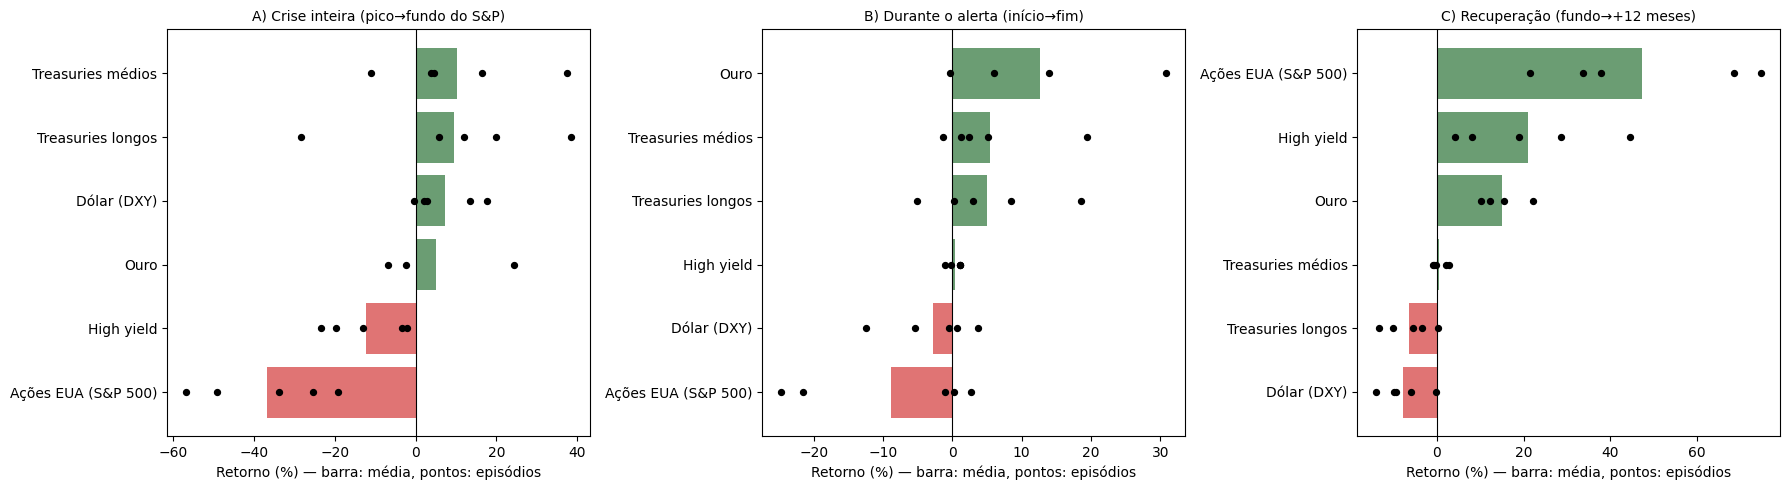

In [5]:

#Qual ativo rendeu mais nas crises?
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#Verificação de pré-requisitos
if "res" not in globals() or "LOOKBACK" not in globals():
    raise RuntimeError("Rode a CÉLULA 1 antes desta (ela cria 'res' com o score). "
                       "Se o Colab reiniciou ou desconectou, rode a Célula 1 de novo.")
USAR_DEMO = globals().get("USAR_DEMO", False)
INICIO = globals().get("INICIO", "1996-01-01")

#Configuração
CLASSES_ALVO = ["CRISE"]        # ex.: ["CRISE", "CORREÇÃO"] para incluir correções
GAP_DIAS     = 30               # junta alertas separados por menos de N dias corridos
MIN_DIAS     = 10               # ignora episódios mais curtos que N dias corridos
RECUP_DIAS   = 365              # janela de recuperação após o fundo

# nome: ticker do Yahoo. Fundos de longa data (VUSTX etc.) dão histórico desde os anos 90;
# ETFs equivalentes: TLT (longos), IEF (médios), HYG (high yield), GLD (ouro)
ATIVOS = {
    "Ações EUA (S&P 500)": "^GSPC",
    "Ouro":                "GC=F",       # futuros, desde ago/2000 (GLD só desde 2004)
    "Treasuries longos":   "VUSTX",
    "Treasuries médios":   "VFITX",
    "High yield":          "VWEHX",
    "Dólar (DXY)":         "DX-Y.NYB",
}

#Dados dos ativos
def baixar_ativos(tickers, inicio):
    import yfinance as yf
    px = yf.download(list(tickers.values()), start=inicio, auto_adjust=True,
                     progress=False)["Close"]
    if isinstance(px, pd.Series):
        px = px.to_frame(list(tickers.values())[0])
    faltando = [n for n, t in tickers.items() if t not in px or px[t].dropna().empty]
    for n in faltando:
        print(f"⚠ Sem dados para {n} ({tickers[n]}) — ignorado.")
    px = px.rename(columns={v: k for k, v in tickers.items()})
    return px.dropna(how="all").ffill(limit=5)

def ativos_demo(idx):
    rng = np.random.default_rng(1)
    base = res["sp500"].reindex(idx).pct_change().fillna(0)
    out = {}
    out["Ações EUA (S&P 500)"] = res["sp500"].reindex(idx)
    out["Ouro"]   = 1500 * (1 + (-0.2 * base + rng.normal(0.0003, 0.006, len(idx)))).cumprod()
    out["Treasuries longos"] = 100 * (1 + (-0.3 * base + rng.normal(0.0002, 0.004, len(idx)))).cumprod()
    return pd.DataFrame(out, index=idx)

px = ativos_demo(res.index) if USAR_DEMO else baixar_ativos(ATIVOS, INICIO)

#Episódios (vindos do Crisis Score)
def achar_episodios(res):
    flag = res["classe"].isin(CLASSES_ALVO)
    grp = (flag != flag.shift()).cumsum()
    brutos = [[g.index[0], g.index[-1]] for _, g in res[flag].groupby(grp[flag])]
    unidos = []
    for s, e in brutos:
        if unidos and (s - unidos[-1][1]).days <= GAP_DIAS:
            unidos[-1][1] = e
        else:
            unidos.append([s, e])
    eps = []
    for s, e in unidos:
        if (e - s).days < MIN_DIAS:
            continue
        pico = res["sp500"].loc[:s].tail(LOOKBACK).idxmax()
        fundo = res["sp500"].loc[pico: e + pd.Timedelta(days=60)].idxmin()
        eps.append(dict(inicio=s, fim=e, pico=pico, fundo=fundo))
    # NOVO: funde episódios cujo trecho pico→fundo se sobrepõe (mesmo mercado baixista)
    eps.sort(key=lambda d: d["pico"])
    out = []
    for ep in eps:
        if out and ep["pico"] <= out[-1]["fundo"]:
            p = out[-1]
            p["inicio"] = min(p["inicio"], ep["inicio"])
            p["fim"] = max(p["fim"], ep["fim"])
            p["fundo"] = res["sp500"].loc[p["pico"]: p["fim"] + pd.Timedelta(days=60)].idxmin()
        else:
            out.append(ep)
    return out

episodios = achar_episodios(res)
if not episodios:
    raise SystemExit("Nenhum episódio encontrado com as classes escolhidas.")

#Retornos por janela
def retorno(serie, ini, fim, tol=7):
    s = serie.dropna()
    if s.empty or fim > s.index[-1] + pd.Timedelta(days=tol):
        return np.nan
    p0 = s.loc[ini: ini + pd.Timedelta(days=tol)]
    p1 = s.loc[fim - pd.Timedelta(days=tol): fim]
    if p0.empty or p1.empty:
        return np.nan
    return p1.iloc[-1] / p0.iloc[0] - 1

JANELAS = {
    "A) Crise inteira (pico→fundo do S&P)": lambda ep: (ep["pico"], ep["fundo"]),
    "B) Durante o alerta (início→fim)":      lambda ep: (ep["inicio"], ep["fim"]),
    "C) Recuperação (fundo→+12 meses)":      lambda ep: (ep["fundo"], ep["fundo"] + pd.Timedelta(days=RECUP_DIAS)),
}

linhas = []
for ep in episodios:
    rotulo = f"{ep['pico'].year}-{ep['fundo'].year} ({ep['pico'].date()}→{ep['fundo'].date()})"
    for jn, fn in JANELAS.items():
        a, b = fn(ep)
        linha = {"episódio": rotulo, "janela": jn}
        for col in px.columns:
            linha[col] = retorno(px[col], a, b)
        linhas.append(linha)
tab = pd.DataFrame(linhas).set_index(["janela", "episódio"])

#Resultados
pd.options.display.float_format = "{:.1%}".format
pd.options.display.width = 200
for jn in JANELAS:
    sub = tab.loc[jn]
    print("\n" + "=" * 90 + f"\n{jn}\n" + "=" * 90)
    print(sub.to_string())
    resumo = pd.DataFrame({
        "média":    sub.mean(),
        "mediana":  sub.median(),
        "% positivo": (sub > 0).sum() / sub.notna().sum(),
        "nº episódios": sub.notna().sum(),
    })
    resumo["nº episódios"] = resumo["nº episódios"].astype(int)
    print("\nResumo:")
    print(resumo.sort_values("média", ascending=False).to_string(
        formatters={"nº episódios": "{:d}".format}))
    melhor = resumo["média"].idxmax()
    print(f"→ Melhor média nesta janela: {melhor} ({resumo.loc[melhor, 'média']:.1%})")

#Gráfico
fig, axes = plt.subplots(1, len(JANELAS), figsize=(6 * len(JANELAS), 5), sharey=False)
for ax, jn in zip(np.atleast_1d(axes), JANELAS):
    sub = tab.loc[jn] * 100
    media = sub.mean().sort_values()
    ax.barh(media.index, media.values,
            color=["#d64545" if v < 0 else "#3a7d44" for v in media.values], alpha=.75)
    for i, nome in enumerate(media.index):
        ax.scatter(sub[nome].dropna().values, [i] * sub[nome].notna().sum(),
                   color="black", s=18, zorder=3)
    ax.axvline(0, color="black", lw=.8)
    ax.set_title(jn, fontsize=10); ax.set_xlabel("Retorno (%) — barra: média, pontos: episódios")
plt.tight_layout(); plt.show()


PARTE 1 — DESEMPENHO POR REGIME  (dias: NORMAL=4168, QUEDA COMUM=2430, CORREÇÃO=783, CRISE=374)

(a) Retorno ANUALIZADO enquanto o mercado está no regime:
             Dólar (DXY)  Ouro  Treasuries médios  Treasuries longos  High yield  Ações EUA (S&P 500)
NORMAL              0.4% 11.8%               0.5%              -2.6%       10.1%                43.3%
QUEDA COMUM         3.1%  8.2%               6.0%              11.1%        5.1%                -9.0%
CORREÇÃO           -7.2% 11.1%              13.5%              19.7%       -7.5%               -52.2%
CRISE               3.0%  5.2%              11.1%              10.6%       -8.4%               -20.5%

(b) Retorno MEDIANO dos 63 pregões SEGUINTES a um dia no regime:
             Dólar (DXY)  Ouro  Treasuries médios  Treasuries longos  High yield  Ações EUA (S&P 500)
NORMAL              0.5%  2.5%               0.6%               0.9%        1.4%                 2.8%
QUEDA COMUM         0.1%  2.6%               1.2%               1

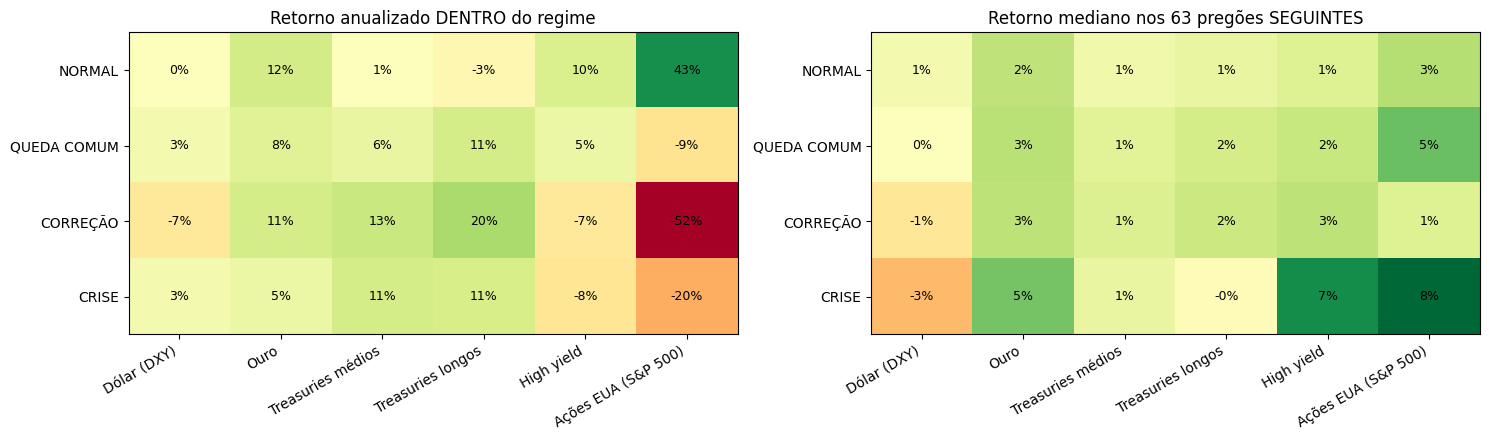


PARTE 2 — A) com spread de crédito — PERÍODOS PARECIDOS COM: HOJE (2026-11-20)
Referência: drawdown=-11.6% | velocity=-11.0% | vix=35.9 | credit=352.0

Análogos (menor distância = mais parecido):
                 classe score distância drawdown velocity  vix credit
data                                                                 
2026-03-27  QUEDA COMUM    18      0.83    -8.7%    -8.2% 31.0  342.0
2025-04-03  QUEDA COMUM    24      1.00   -12.2%   -12.2% 30.0  401.0
2024-08-05  QUEDA COMUM    21      1.10    -8.5%    -5.2% 38.6  393.0

------------------------------------------------------------------------------------------
Horizonte: 1 mês
------------------------------------------------------------------------------------------
ativo       Dólar (DXY)  Ouro  Treasuries médios  Treasuries longos  High yield  Ações EUA (S&P 500)
data                                                                                                
2024-08-05        -1.3%  3.3%               0.5%   

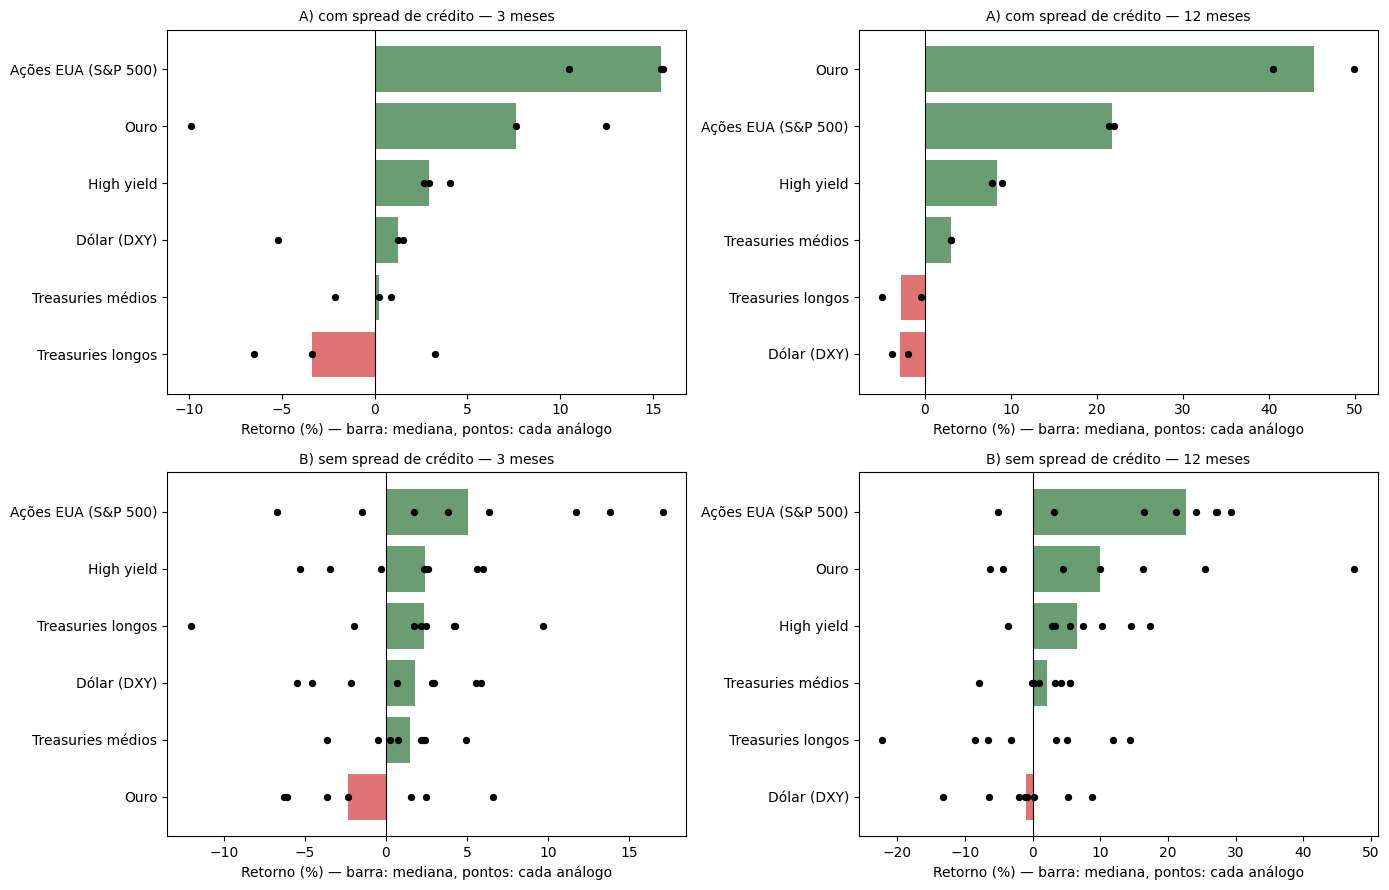

In [6]:

#Desempenho por regime + períodos parecidos com hoje
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

for _nome in ("res", "px", "LOOKBACK"):
    if _nome not in globals():
        raise RuntimeError(f"Falta '{_nome}'. Rode a CÉLULA 1 e depois a CÉLULA 3 antes desta "
                           "(se o Colab reiniciou, rode ambas de novo).")

#Configuração
QUEDA_MIN_DD   = -0.03     # drawdown a partir do qual o dia deixa de ser "NORMAL"
FWD_REGIME     = 63        # pregões (~3 meses) para o retorno futuro por regime
N_ANALOGOS     = 8         # quantos períodos parecidos buscar
SEPARACAO_DIAS = 60        # distância mínima (dias corridos) entre análogos
EXCLUIR_ULT_DIAS = 45      # ignora os últimos N dias como candidatos
FRACAO_DD_MIN  = 0.6       # NOVO: análogo precisa ter drawdown >= 60% do atual (evita quedas rasas)
HORIZONTES     = {"1 mês": 30, "3 meses": 90, "6 meses": 180, "12 meses": 365}
# NOVO: dois cenários de busca. Peso 0 = sinal ignorado. "B" ignora o spread de crédito,
# o que permite achar períodos como 2008, 2020 e 2022 (quando o spread era bem maior).
CENARIOS = {
    "A) com spread de crédito": {"drawdown": 1, "velocity": 1, "vix": 1, "credit": 1},
    "B) sem spread de crédito": {"drawdown": 1, "velocity": 1, "vix": 1, "credit": 0},
}
# Cenário hipotético em vez de "hoje" (None = último dia). Ex.:
ATUAL = None   # {"drawdown": -0.115, "velocity": -0.11, "vix": 25, "credit": 450}

REGIMES = ["NORMAL", "QUEDA COMUM", "CORREÇÃO", "CRISE"]
ativos = [c for c in px.columns]
precos = px.reindex(res.index).ffill(limit=5)

# PARTE 1 — Quem performa melhor em cada regime

reg = res["classe"].copy()
reg[(reg == "QUEDA COMUM") & (res["drawdown"] > QUEDA_MIN_DD)] = "NORMAL"
reg[res["classe"] == "sem dados"] = np.nan

ret_d = precos.pct_change()
fwd = precos.shift(-FWD_REGIME) / precos - 1

anual = pd.DataFrame(index=REGIMES, columns=ativos, dtype=float)
fwd_med = anual.copy(); fwd_pos = anual.copy(); dias = {}
for r in REGIMES:
    m = (reg == r)
    dias[r] = int(m.sum())
    for a in ativos:
        x = ret_d.loc[m, a].dropna()
        if len(x) >= 20:
            anual.loc[r, a] = (1 + x).prod() ** (252 / len(x)) - 1
        y = fwd.loc[m, a].dropna()
        if len(y) >= 20:
            fwd_med.loc[r, a] = y.median()
            fwd_pos.loc[r, a] = (y > 0).mean()

pd.options.display.float_format = "{:.1%}".format
pd.options.display.width = 200
print("=" * 90)
print("PARTE 1 — DESEMPENHO POR REGIME  (dias: " + ", ".join(f"{r}={dias[r]}" for r in REGIMES) + ")")
print("=" * 90)
print("\n(a) Retorno ANUALIZADO enquanto o mercado está no regime:")
print(anual.to_string())
print(f"\n(b) Retorno MEDIANO dos {FWD_REGIME} pregões SEGUINTES a um dia no regime:")
print(fwd_med.to_string())
print(f"\n(c) % de vezes em que o ativo subiu nos {FWD_REGIME} pregões seguintes:")
print(fwd_pos.to_string())
print("\nMelhor ativo por regime:")
for r in REGIMES:
    if anual.loc[r].notna().any():
        b1 = anual.loc[r].idxmax()
        b2 = fwd_med.loc[r].idxmax() if fwd_med.loc[r].notna().any() else "—"
        print(f"  {r:<12} durante: {b1:<22} | nos 3 meses seguintes: {b2}")

fig, axs = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, tab_, tit in [(axs[0], anual, "Retorno anualizado DENTRO do regime"),
                      (axs[1], fwd_med, f"Retorno mediano nos {FWD_REGIME} pregões SEGUINTES")]:
    v = tab_.astype(float).values
    lim = np.nanmax(np.abs(v)) if np.isfinite(v).any() else 1
    ax.imshow(v, cmap="RdYlGn", vmin=-lim, vmax=lim, aspect="auto")
    ax.set_xticks(range(len(ativos))); ax.set_xticklabels(ativos, rotation=30, ha="right")
    ax.set_yticks(range(len(REGIMES))); ax.set_yticklabels(REGIMES); ax.set_title(tit)
    for i in range(v.shape[0]):
        for j in range(v.shape[1]):
            if np.isfinite(v[i, j]):
                ax.text(j, i, f"{v[i, j]:.0%}", ha="center", va="center", fontsize=9)
plt.tight_layout(); plt.show()

# PARTE 2 — Períodos históricos parecidos com o momento atual

def preco_em(serie, d, tol=7):
    s = serie.dropna().loc[:d]
    return s.iloc[-1] if len(s) and (d - s.index[-1]).days <= tol else np.nan

def ret_fwd(serie, d, dias_):
    s = serie.dropna()
    if s.empty or d + pd.Timedelta(days=dias_) > s.index[-1] + pd.Timedelta(days=7):
        return np.nan
    p0, p1 = preco_em(s, d), preco_em(s, d + pd.Timedelta(days=dias_))
    return p1 / p0 - 1 if np.isfinite(p0) and np.isfinite(p1) else np.nan

amostra = precos.index[::15]
baseline = {hn: {a: np.nanmean([ret_fwd(precos[a], d, hd) for d in amostra]) for a in ativos}
            for hn, hd in HORIZONTES.items()}

def rodar_cenario(nome, pesos):
    feats = [k for k, w in pesos.items()
             if w > 0 and k in res and res[k].notna().sum() > 100 and (not ATUAL or k in ATUAL)]
    if len(feats) < 2:
        print(f"\n[{nome}] sinais insuficientes — pulado."); return None
    w = np.array([pesos[k] for k in feats], dtype=float)
    base = res[feats].dropna()
    mu, sd = base.mean(), base.std()
    atual = pd.Series({k: ATUAL[k] for k in feats}) if ATUAL else base.iloc[-1]
    rot = "CENÁRIO INFORMADO" if ATUAL else f"HOJE ({base.index[-1].date()})"
    z = (base - mu) / sd
    z0 = (atual - mu) / sd
    dist = np.sqrt((w * (z - z0) ** 2).sum(axis=1) / w.sum())

    dd_atual = atual["drawdown"] if "drawdown" in atual else res["drawdown"].dropna().iloc[-1]
    ok = (res["drawdown"].reindex(dist.index) <= FRACAO_DD_MIN * dd_atual) & \
         (dist.index <= base.index[-1] - pd.Timedelta(days=EXCLUIR_ULT_DIAS))
    cands = dist[ok].sort_values()
    escolhidos = []
    for d, v in cands.items():
        if all(abs((d - e).days) > SEPARACAO_DIAS for e, _ in escolhidos):
            escolhidos.append((d, v))
        if len(escolhidos) == N_ANALOGOS:
            break

    print("\n" + "=" * 90)
    print(f"PARTE 2 — {nome} — PERÍODOS PARECIDOS COM: {rot}")
    print("=" * 90)
    print("Referência: " + " | ".join(
        f"{k}={atual[k]:.1%}" if k in ("drawdown", "velocity") else f"{k}={atual[k]:.1f}" for k in feats))
    if len(escolhidos) < 3:
        print("⚠ Poucos análogos encontrados — afrouxe FRACAO_DD_MIN."); return None

    linhas = []
    for d, v in escolhidos:
        row = {"data": d.date(), "classe": res.loc[d, "classe"], "score": res.loc[d, "score"], "distância": v}
        for k in feats:
            row[k] = res.loc[d, k]
        linhas.append(row)
    an = pd.DataFrame(linhas).set_index("data").sort_values("distância")
    fmt = {k: "{:.1%}".format for k in ("drawdown", "velocity") if k in an}
    fmt.update({"score": "{:.0f}".format, "distância": "{:.2f}".format})
    fmt.update({k: "{:.1f}".format for k in ("vix", "credit") if k in an})
    print("\nAnálogos (menor distância = mais parecido):")
    print(an.to_string(formatters=fmt))

    reg_ = [{"data": d.date(), "horizonte": hn, "ativo": a, "ret": ret_fwd(precos[a], d, hd)}
            for d, _ in escolhidos for hn, hd in HORIZONTES.items() for a in ativos]
    rf = pd.DataFrame(reg_)
    resumos = {}
    for hn in HORIZONTES:
        sub = rf[rf.horizonte == hn].pivot(index="data", columns="ativo", values="ret")[ativos]
        resumo = pd.DataFrame({
            "média": sub.mean(), "mediana": sub.median(),
            "% positivo": (sub > 0).sum() / sub.notna().sum(),
            "n": sub.notna().sum().astype(int), "média geral*": pd.Series(baseline[hn])})
        resumos[hn] = (sub, resumo)
        print("\n" + "-" * 90 + f"\nHorizonte: {hn}\n" + "-" * 90)
        print(sub.to_string())
        print("\nResumo:")
        print(resumo.sort_values("mediana", ascending=False).to_string(formatters={"n": "{:d}".format}))
        if resumo["n"].max() < 5:
            print("⚠ Menos de 5 análogos com dados neste horizonte — evite conclusões.")
    print("\n* média geral = retorno médio do ativo em qualquer época (referência).")
    return rot, resumos

resultados = {}
for nome, pesos in CENARIOS.items():
    out = rodar_cenario(nome, pesos)
    if out:
        resultados[nome] = out

#Gráfico dos análogos (um painel por cenário e horizonte)
hs = ["3 meses", "12 meses"]
if resultados:
    fig, axes = plt.subplots(len(resultados), len(hs), figsize=(7 * len(hs), 4.5 * len(resultados)),
                             squeeze=False)
    for i, (nome, (rot, resumos)) in enumerate(resultados.items()):
        for j, hn in enumerate(hs):
            ax = axes[i][j]
            sub, resumo = resumos[hn]
            med = (resumo["mediana"] * 100).sort_values()
            ax.barh(med.index, med.values,
                    color=["#d64545" if v < 0 else "#3a7d44" for v in med.values], alpha=.75)
            for k, nome_a in enumerate(med.index):
                vals = (sub[nome_a].dropna() * 100).values
                ax.scatter(vals, [k] * len(vals), color="black", s=18, zorder=3)
            ax.axvline(0, color="black", lw=.8)
            ax.set_title(f"{nome} — {hn}", fontsize=10)
            ax.set_xlabel("Retorno (%) — barra: mediana, pontos: cada análogo")
    plt.tight_layout(); plt.show()
